# Stress questionnaires (PSQ, TICS): overview

PSQ = Perceived Stress Questionnaire (4 subscales + overall score, 0-100). TICS = Trier Inventory for Chronic Stress (9 subscales + a screening scale).
**Only group-level numbers and plots are shown**, no IDs. Run `scripts/clean_stress.py` first.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())   # works from any folder
RES = ROOT / "analysis/stress_questionnaires/results"
clean = pd.read_csv(ROOT / "data/derived/stress_questionnaires/stress_clean.csv")
print(f"clean table: {clean.shape[0]} participants x {clean.shape[1] - 1} scores; complete PSQ+TICS: {clean.dropna().shape[0]}")

clean table: 227 participants x 15 scores; complete PSQ+TICS: 220


## 1. What was checked, and the answers

In [2]:
pd.read_csv(RES / "score_checks.csv")

,check,result,conclusion
0,PSQ_OverallScore = mean of the 4 subscales,0 of 220 rows within 0.01,no
1,"PSQ_OverallScore = mean of Worries, Tension, D...",220 of 220 rows within 0.01,yes
2,TICS_ScreeningScale = sum of the 9 subscales,0 of 220 rows equal,no
3,"PSQ_OverallScore vs TICS_ScreeningScale, all","Pearson r = 0.763, Spearman rho = 0.737, n = 220",strong positive
4,"PSQ_OverallScore vs TICS_ScreeningScale, witho...","Pearson r = 0.765, n = 219",almost unchanged
5,IDs in PSQ/TICS not in META,0 / 0,all match
6,Decimal commas in the raw files,"PSQ 0, TICS 0",none


## 2. Score distributions
`n_beyond_3sd` counts unusually extreme values (more than 3 SD from the mean); they were kept, not removed.

In [3]:
d = pd.read_csv(RES / "score_descriptives.csv")
d[d.group == "all"].drop(columns="group").set_index("variable")

,n,missing,mean,sd,min,median,max,skew,n_beyond_3sd
variable,,,,,,,,,
PSQ_Worries,220,7,26.273,18.576,0.0,26.667,100.000,0.848,2
PSQ_Tension,220,7,28.212,18.938,0.0,26.667,93.333,0.859,2
PSQ_Joy,220,7,66.970,18.051,20.0,66.667,100.000,-0.193,0
PSQ_Demands,220,7,32.879,20.397,0.0,33.333,100.000,0.553,1
PSQ_OverallScore,220,7,30.098,15.474,0.0,26.667,75.000,0.643,0
TICS_WorkOverload,220,7,9.514,6.690,0.0,9.000,32.000,0.739,3
TICS_SocialOverload,220,7,7.141,4.461,0.0,7.000,24.000,0.541,2
TICS_PressuereToPerform,220,7,13.995,6.442,0.0,15.000,36.000,0.062,2
TICS_WorkDiscontent,220,7,10.645,5.676,0.0,10.000,32.000,0.750,1


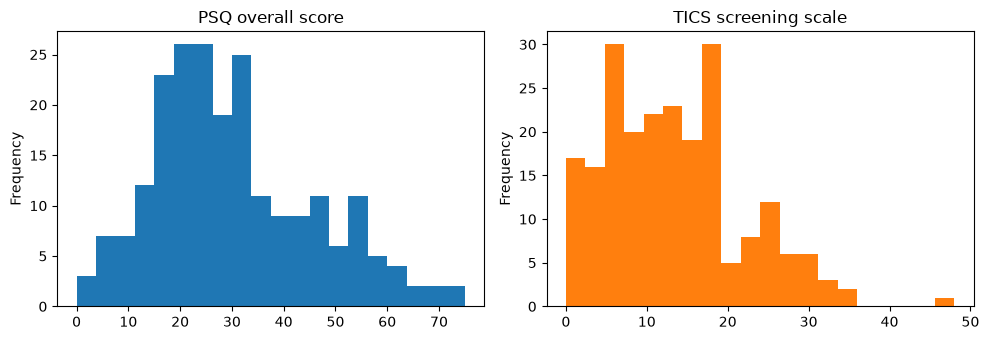

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
clean.PSQ_OverallScore.plot.hist(bins=20, ax=ax[0], title="PSQ overall score")
clean.TICS_ScreeningScale.plot.hist(bins=20, ax=ax[1], color="C1", title="TICS screening scale"); plt.tight_layout(); plt.show()

## 3. Do the two questionnaires agree?
Each dot is one person (no labels). They measure related things, so a strong positive relation is expected.

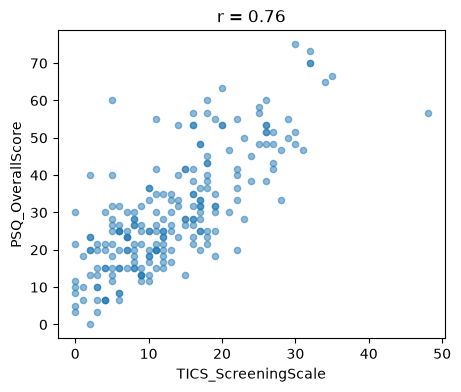

,PSQ_Worries,PSQ_Tension,PSQ_Joy,PSQ_Demands,PSQ_OverallScore
PSQ_Worries,1.00,0.70,-0.52,0.53,0.84
PSQ_Tension,0.70,1.00,-0.56,0.67,0.90
PSQ_Joy,-0.52,-0.56,1.00,-0.33,-0.73
PSQ_Demands,0.53,0.67,-0.33,1.00,0.79
PSQ_OverallScore,0.84,0.90,-0.73,0.79,1.00


In [5]:
ax = clean.plot.scatter(x="TICS_ScreeningScale", y="PSQ_OverallScore", alpha=0.5, figsize=(5, 4))
ax.set_title(f"r = {clean[['TICS_ScreeningScale', 'PSQ_OverallScore']].corr().iloc[0, 1]:.2f}"); plt.show()
clean.drop(columns="ID").corr().round(2).iloc[:5, :5]

## 4. PSQ in detail (teammate's analysis, `scripts/psq_eda.py`)
Quartiles and correlations of the four PSQ subscales and the total. Joy runs opposite to stress (higher Joy = less stress).

In [6]:
display(pd.read_csv(RES / "PSQ_summary_statistics.csv").round(2).set_index("Measure"))
pd.read_csv(RES / "PSQ_pearson_correlations.csv").round(2).set_index("Measure")

,N,Missing,Mean,SD,Q1,Median,Q3,IQR,Min,Max,Outside_1p5_IQR
Measure,,,,,,,,,,,
Worries,220,7,26.27,18.58,13.33,26.67,40.00,26.67,0.0,100.00,2
Tension,220,7,28.21,18.94,13.33,26.67,40.00,26.67,0.0,93.33,2
Joy,220,7,66.97,18.05,53.33,66.67,80.00,26.67,20.0,100.00,0
Demands,220,7,32.88,20.40,20.00,33.33,46.67,26.67,0.0,100.00,1
Total score,220,7,30.10,15.47,20.00,26.67,40.00,20.00,0.0,75.00,2


,Worries,Tension,Joy,Demands,Total score
Measure,,,,,
Worries,1.00,0.70,-0.52,0.53,0.84
Tension,0.70,1.00,-0.56,0.67,0.90
Joy,-0.52,-0.56,1.00,-0.33,-0.73
Demands,0.53,0.67,-0.33,1.00,0.79
Total score,0.84,0.90,-0.73,0.79,1.00


![PSQ distributions](figures/02_PSQ_distributions.png)

![PSQ correlations](figures/04_PSQ_correlations.png)

## 5. PSQ by age group and recorded gender (teammate's `lemon_psychology_eda.py`)

In [7]:
pd.read_csv(RES / "psq_descriptives.csv").query("score == 'PSQ_OverallScore'")[["group", "valid_n", "mean", "sd", "median", "q1", "q3"]].round(1)

,group,valid_n,mean,sd,median,q1,q3
0,all,220,30.1,15.5,26.7,20.0,40.0
1,younger,148,33.2,15.5,30.0,21.7,43.3
2,older,72,23.8,13.5,21.7,14.6,30.0
3,female,80,30.8,15.9,28.3,20.0,40.0
4,male,140,29.7,15.3,25.8,19.6,40.0


![PSQ by age](figures/psq_by_age.png)

![PSQ by gender](figures/psq_by_gender.png)

![PSQ availability](figures/psq_score_availability.png)

## 6. Coverage of all 23 questionnaires

In [8]:
pd.read_csv(RES / "questionnaire_coverage.csv")[["questionnaire", "score_columns", "any_score_n", "complete_score_n"]]

,questionnaire,score_columns,any_score_n,complete_score_n
0,BISBAS,4,220,220
1,CERQ,9,220,220
2,COPE,14,219,219
3,ERQ,2,220,220
4,F-SozU_K-22,5,220,220
5,FEV,3,220,220
6,FTP,1,142,142
7,LOT-R,3,220,220
8,MARS,6,208,208
9,MDBF_Day1,3,226,223


## 7. Younger vs older (this project's table)

In [9]:
d[d.variable.isin(["PSQ_OverallScore", "TICS_ScreeningScale"])].pivot(index="variable", columns="group", values=["n", "mean", "sd"]).round(1)

n                                mean                                  sd                              
group                  all older (55-80) younger (20-40)   all older (55-80) younger (20-40)   all older (55-80) younger (20-40)
variable                                                                                                                        
PSQ_OverallScore     220.0          72.0           148.0  30.1          23.8            33.2  15.5          13.5            15.5
TICS_ScreeningScale  220.0          72.0           148.0  13.3          10.7            14.5   8.5           7.1             8.9